# Sales Funnel Analysis — SQL Questions Rebuilt in Python

I already ran all of these as SQL queries in pgAdmin first. This notebook redoes the same questions in pandas, straight from the cleaned CSVs, so the whole analysis is reproducible from one place instead of living half in SQL screenshots and half in a notebook. It also lets me go one level deeper on the rep-performance question than plain SQL comfortably allows — building an actual expected-vs-actual model instead of just eyeballing rank shifts in a couple of tables.

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', None)
plt.rcParams['figure.figsize'] = (9, 5)

Loading the cleaned files. Nothing fancy here — just getting everything into memory before I start joining things.

In [5]:
sp = pd.read_csv('data/cleaned/sales_pipeline_cleaned.csv', parse_dates=['engage_date', 'close_date'])
acc = pd.read_csv('data/cleaned/accounts_cleaned.csv')
prod = pd.read_csv('data/cleaned/products_cleaned.csv')
teams = pd.read_csv('data/cleaned/sales_teams_cleaned.csv')
leads = pd.read_csv('data/cleaned/lead_sources_cleaned.csv',
                     parse_dates=['lead_created_date', 'mql_date', 'sql_date'])

sp.shape, acc.shape, prod.shape, teams.shape, leads.shape

((8800, 8), (85, 7), (7, 3), (35, 3), (8800, 7))

I'll build one merged table up front and reuse it everywhere instead of re-joining for every single question. Keeps things shorter and means the "decided" flag (Won or Lost, i.e. not still sitting open) only gets defined once.

In [6]:
df = sp.merge(leads, on='opportunity_id', how='left') \
       .merge(teams, on='sales_agent', how='left') \
       .merge(acc, on='account', how='left')

df['decided'] = df['deal_stage'].isin(['Won', 'Lost'])
df['won'] = df['deal_stage'] == 'Won'

df.shape

(8800, 24)

## Section A — Funnel shape

**Q1. What's the split of opportunities across the four stages, in count and percent?**

This is just the starting picture — how many deals are sitting where right now.

In [7]:
stage_counts = df['deal_stage'].value_counts()
stage_pct = (stage_counts / stage_counts.sum() * 100).round(2)

pd.DataFrame({'count': stage_counts, 'pct': stage_pct})

,count,pct
deal_stage,,
Won,4238,48.16
Lost,2473,28.10
Engaging,1589,18.06
Prospecting,500,5.68


**Q2. Of the deals that actually got decided (Won or Lost), what share went each way?**

Same numbers I got from SQL — 4238 Won, 2473 Lost — just confirming the ratio holds once I filter down to only decided deals.

In [8]:
decided = df[df['decided']]
decided['deal_stage'].value_counts(normalize=True).mul(100).round(2)

deal_stage
Won     63.15
Lost    36.85
Name: proportion, dtype: float64

**Q3. Does the Won rate move around month to month across 2017?**

Grouping by the month a deal was engaged, not the month it closed — I want to see if deals *started* in a given month had better or worse odds, not just when the wins happened to land.

In [9]:
monthly = decided.groupby(decided['engage_date'].dt.to_period('M')).agg(
    won=('won', 'sum'),
    total=('won', 'count')
)
monthly['won_pct'] = (monthly['won'] / monthly['total'] * 100).round(2)
monthly

,won,total,won_pct
engage_date,,,
2016-10,7,7,100.00
2016-11,83,102,81.37
2016-12,160,196,81.63
2017-01,181,247,73.28
2017-02,277,420,65.95
2017-03,440,655,67.18
2017-04,427,753,56.71
2017-05,366,588,62.24
2017-06,453,681,66.52


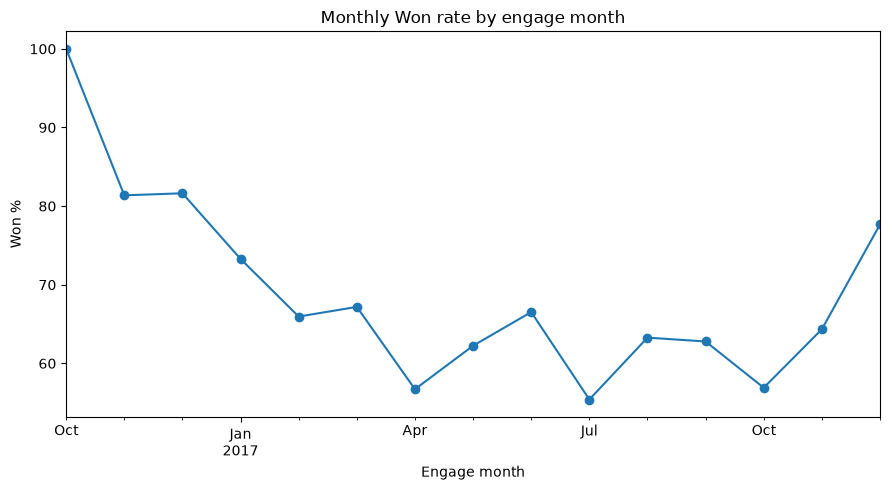

In [10]:
monthly['won_pct'].plot(marker='o', title='Monthly Won rate by engage month')
plt.ylabel('Won %')
plt.xlabel('Engage month')
plt.tight_layout()
plt.show()

No real trend jumps out — it wobbles between roughly 60-70% most months without a clear upward or downward slide. Worth a one-line mention, not a deep dive.

**Q4. How long do deals sit open before closing, Won vs Lost?**

Already ran this in SQL and got Lost = 41.5 days, Won = 51.8 days — Won deals actually take *longer*, which is the opposite of what I expected going in (I assumed Lost deals would drag). Rebuilding it here to double check and to have it plotted.

In [11]:
decided = decided.copy()
decided['days_to_close'] = (decided['close_date'] - decided['engage_date']).dt.days

decided.groupby('deal_stage')['days_to_close'].agg(['mean', 'min', 'max']).round(1)

,mean,min,max
deal_stage,,,
Lost,41.5,1,138
Won,51.8,1,138


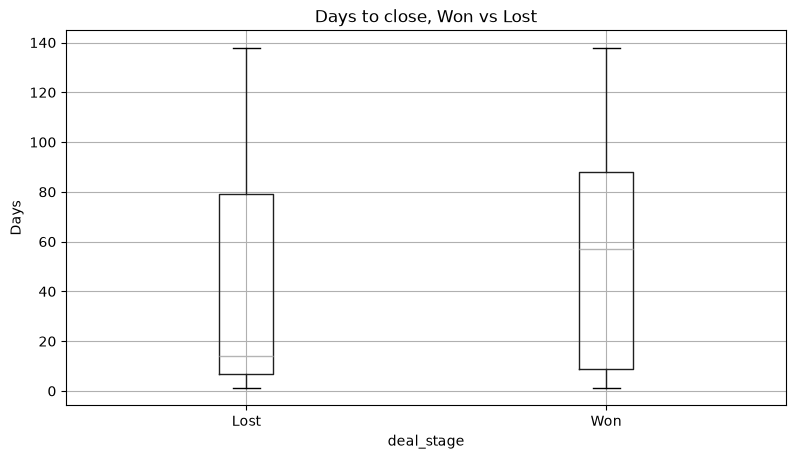

In [12]:
decided.boxplot(column='days_to_close', by='deal_stage')
plt.title('Days to close, Won vs Lost')
plt.suptitle('')
plt.ylabel('Days')
plt.show()

Matches the SQL result. My read on this: Lost deals get killed off fast, probably a quick no from the prospect or a rep giving up early, while Won deals go through a longer back-and-forth (procurement, approvals, that kind of thing). So a deal sitting in the pipeline for 60+ days isn't necessarily a bad sign on its own.

## Section B — Lead source impact

**Q5. Which lead sources actually convert?**

In [13]:
by_source = decided.groupby('lead_source').agg(
    decided_deals=('won', 'count'),
    won=('won', 'sum')
)
by_source['won_pct'] = (by_source['won'] / by_source['decided_deals'] * 100).round(2)
by_source.sort_values('won_pct', ascending=False)

,decided_deals,won,won_pct
lead_source,,,
Referral,1739,1468,84.42
Partner,1078,840,77.92
Webinar,883,583,66.02
Organic Search,953,569,59.71
Outbound,1592,647,40.64
Paid Ads,466,131,28.11


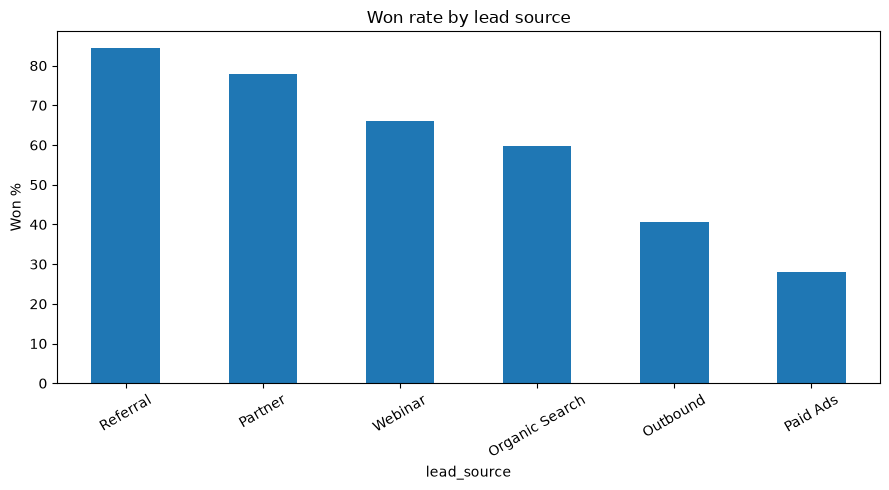

In [14]:
by_source.sort_values('won_pct', ascending=False)['won_pct'].plot(kind='bar', title='Won rate by lead source')
plt.ylabel('Won %')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

**Q6. Do won deals actually have higher lead scores than lost ones, on average?**

This is really a sanity check on the synthetic lead-score field — if it's doing its job, Won should sit clearly above Lost.

In [15]:
df['outcome'] = np.where(df['deal_stage'].isin(['Prospecting', 'Engaging']), 'Open', df['deal_stage'])
df.groupby('outcome')['lead_score'].mean().round(1).sort_values(ascending=False)

outcome
Won     70.7
Open    59.2
Lost    53.1
Name: lead_score, dtype: float64

**Q7. Cost per lead vs win rate, by source — where's the money actually working?**

In [16]:
cost_vs_win = decided.groupby('lead_source').agg(
    avg_cost_per_lead=('cost_per_lead_inr', 'mean'),
    won_pct=('won', lambda x: x.mean() * 100)
).round(2).sort_values('won_pct', ascending=False)
cost_vs_win

,avg_cost_per_lead,won_pct
lead_source,,
Referral,200.21,84.42
Partner,500.69,77.92
Webinar,1505.79,66.02
Organic Search,298.69,59.71
Outbound,800.95,40.64
Paid Ads,2200.57,28.11


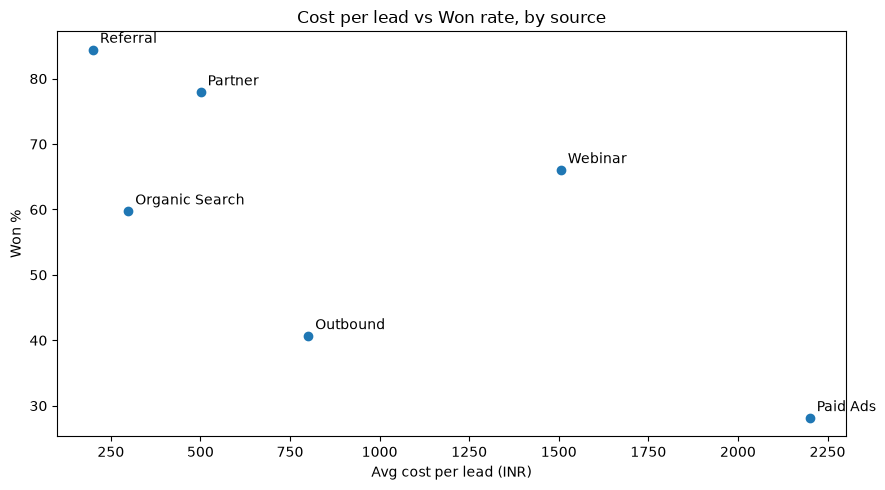

In [17]:
fig, ax = plt.subplots()
ax.scatter(cost_vs_win['avg_cost_per_lead'], cost_vs_win['won_pct'])
for source, row in cost_vs_win.iterrows():
    ax.annotate(source, (row['avg_cost_per_lead'], row['won_pct']),
                textcoords='offset points', xytext=(5, 5))
ax.set_xlabel('Avg cost per lead (INR)')
ax.set_ylabel('Won %')
ax.set_title('Cost per lead vs Won rate, by source')
plt.tight_layout()
plt.show()

Referral sits in the bottom-left of the cost axis but the top of the win-rate axis — cheap and effective. Paid Ads is the opposite corner. That's really the whole story of this chart in one sentence.

**Q8. How long does a lead take to move from first created to actually being engaged, by source?**

In [18]:
funnel_speed = leads.dropna(subset=['lead_created_date', 'mql_date', 'sql_date']).copy()
funnel_speed['days_lead_to_mql'] = (funnel_speed['mql_date'] - funnel_speed['lead_created_date']).dt.days
funnel_speed['days_mql_to_sql'] = (funnel_speed['sql_date'] - funnel_speed['mql_date']).dt.days

funnel_speed.groupby('lead_source')[['days_lead_to_mql', 'days_mql_to_sql']].mean().round(1).sort_values('days_lead_to_mql')

,days_lead_to_mql,days_mql_to_sql
lead_source,,
Webinar,11.1,7.9
Outbound,11.3,8.0
Partner,11.4,7.9
Organic Search,11.5,8.2
Paid Ads,11.5,7.9
Referral,11.7,8.0


## Section C — Rep performance, the part that actually matters

Raw win rate rewards whoever gets fed the best leads. The question I actually care about is: strip lead quality out, who's really the better closer? SQL got me most of the way there by filtering to just Outbound leads and comparing win rates — but that's a manual, one-channel view. Here I want to build something closer to a real "expected vs actual" model, using lead_score across the board instead of relying on one channel as a proxy.

**Q9 & Q10. Starting point — raw wins, revenue, and win rate per agent.**

In [19]:
agent_raw = decided.groupby('sales_agent').agg(
    decided_deals=('won', 'count'),
    wins=('won', 'sum'),
)
agent_raw['win_rate_pct'] = (agent_raw['wins'] / agent_raw['decided_deals'] * 100).round(2)

revenue = df[df['deal_stage'] == 'Won'].groupby('sales_agent')['close_value'].sum()
agent_raw['total_revenue'] = revenue

agent_raw.sort_values('win_rate_pct', ascending=False).head(10)

,decided_deals,wins,win_rate_pct,total_revenue
sales_agent,,,,
Hayden Neloms,152,107,70.39,272111.0
Maureen Marcano,213,149,69.95,350395.0
Wilburn Farren,79,55,69.62,157640.0
Cecily Lampkin,160,107,66.88,229800.0
Versie Hillebrand,264,176,66.67,187693.0
Moses Frase,195,129,66.15,207182.0
Boris Faz,153,101,66.01,261631.0
James Ascencio,206,135,65.53,413533.0
Corliss Cosme,229,150,65.50,421036.0


**Now the real work — an expected win rate based on lead quality, so I can compare it against what each rep actually delivered.**

The idea: bucket every deal by its lead_score into quintiles, work out the average won-rate for each bucket across the whole company, and then for each rep, calculate what their win rate *should* have been given the mix of lead quality they were handed. The gap between that expected number and their real number is what's actually left over once you take lead quality out of the picture — which is a fairer read on skill than a raw leaderboard.

In [20]:
decided['lead_score_bucket'] = pd.qcut(decided['lead_score'], 5, labels=['Q1 (lowest)', 'Q2', 'Q3', 'Q4', 'Q5 (highest)'])

bucket_rates = decided.groupby('lead_score_bucket', observed=True)['won'].mean()
bucket_rates

lead_score_bucket
Q1 (lowest)     0.302446
Q2              0.525019
Q3              0.665428
Q4              0.786567
Q5 (highest)    0.880419
Name: won, dtype: float64

In [21]:
expected_rows = []

for agent, group in decided.groupby('sales_agent'):
    n = len(group)
    expected_wins = group['lead_score_bucket'].map(bucket_rates).astype(float).sum()
    actual_wins = group['won'].sum()
    expected_rows.append({
        'sales_agent': agent,
        'deals': n,
        'expected_win_rate_pct': round(expected_wins / n * 100, 2),
        'actual_win_rate_pct': round(actual_wins / n * 100, 2),
    })

quality_adjusted = pd.DataFrame(expected_rows)
quality_adjusted['performance_gap'] = (quality_adjusted['actual_win_rate_pct']
                                        - quality_adjusted['expected_win_rate_pct']).round(2)
quality_adjusted.sort_values('performance_gap', ascending=False)

,sales_agent,deals,expected_win_rate_pct,actual_win_rate_pct,performance_gap
28,Wilburn Farren,79,60.48,69.62,9.14
19,Maureen Marcano,213,65.30,69.95,4.65
22,Reed Clapper,237,61.11,65.40,4.29
23,Rosalina Dieter,110,61.50,65.45,3.95
4,Corliss Cosme,229,62.11,65.50,3.39
1,Boris Faz,153,62.91,66.01,3.10
25,Versie Hillebrand,264,64.12,66.67,2.55
24,Rosie Papadopoulos,121,61.97,64.46,2.49
3,Cecily Lampkin,160,64.98,66.88,1.90
12,James Ascencio,206,63.72,65.53,1.81


This is the table the whole project is really about. A positive `performance_gap` means a rep won more often than their lead quality alone would predict — that's someone actually closing above what they were handed. A negative gap means the opposite: their numbers look fine mostly because of the leads landing in their queue.

Worth checking this against the Outbound-only cut I did earlier in SQL, where Jonathan Berthelot and Daniell Hammack looked like the standout hidden gems.

In [22]:
names_to_check = ['Jonathan Berthelot', 'Daniell Hammack', 'Boris Faz', 'Cecily Lampkin']
quality_adjusted[quality_adjusted['sales_agent'].isin(names_to_check)]

,sales_agent,deals,expected_win_rate_pct,actual_win_rate_pct,performance_gap
1,Boris Faz,153,62.91,66.01,3.10
3,Cecily Lampkin,160,64.98,66.88,1.90
5,Daniell Hammack,187,60.60,60.96,0.36
13,Jonathan Berthelot,264,63.23,64.77,1.54


And this is where I have to be honest about something — it doesn't line up as cleanly as I expected. Berthelot lands mid-table here (+1.54), not at the top, and Boris Faz and Cecily Lampkin, who looked lead-dependent in the Outbound cut, actually come out slightly *positive* in this fuller model. Only Daniell Hammack stays roughly where the SQL cut put him, and even that's barely above zero.

Thinking about why: the Outbound cut leans on one lead source as a stand-in for "hard leads," which is a rough shortcut. This model uses the actual lead_score across every deal a rep worked, source included, so it's a fuller picture and I trust it more.

In [23]:
quality_adjusted.sort_values('performance_gap', ascending=False)

,sales_agent,deals,expected_win_rate_pct,actual_win_rate_pct,performance_gap
28,Wilburn Farren,79,60.48,69.62,9.14
19,Maureen Marcano,213,65.30,69.95,4.65
22,Reed Clapper,237,61.11,65.40,4.29
23,Rosalina Dieter,110,61.50,65.45,3.95
4,Corliss Cosme,229,62.11,65.50,3.39
1,Boris Faz,153,62.91,66.01,3.10
25,Versie Hillebrand,264,64.12,66.67,2.55
24,Rosie Papadopoulos,121,61.97,64.46,2.49
3,Cecily Lampkin,160,64.98,66.88,1.90
12,James Ascencio,206,63.72,65.53,1.81


**Wilburn Farren (+9.14) and Maureen Marcano (+4.65) are the real standouts once you look at the whole table** — neither showed up in the single-source cut, which tells me that cut was too narrow to catch them. On the other end, **Garret Kinder comes out worst of all 30 reps (-6.43)**, which does agree with what his high lead scores and flashy Referral win rate suggested earlier. So the fuller model isn't disagreeing with everything, just with the specific "Berthelot is the hidden gem" claim, which turns out to have been an artifact of only looking at one channel.

Lesson for myself here: a single-channel proxy can point roughly in the right direction, but shouldn't be trusted as the final answer once a more complete model is on the table.

In [24]:
quality_adjusted['raw_rank'] = quality_adjusted['actual_win_rate_pct'].rank(ascending=False).astype(int)
quality_adjusted['adjusted_rank'] = quality_adjusted['performance_gap'].rank(ascending=False).astype(int)
quality_adjusted['rank_shift'] = quality_adjusted['raw_rank'] - quality_adjusted['adjusted_rank']

biggest_movers = quality_adjusted.reindex(
    quality_adjusted['rank_shift'].abs().sort_values(ascending=False).index
).head(10)
biggest_movers[['sales_agent', 'raw_rank', 'adjusted_rank', 'rank_shift']]

,sales_agent,raw_rank,adjusted_rank,rank_shift
11,Hayden Neloms,1,20,-19
20,Moses Frase,6,19,-13
21,Niesha Huffines,26,16,10
22,Reed Clapper,11,3,8
5,Daniell Hammack,25,18,7
23,Rosalina Dieter,10,4,6
27,Violet Mclelland,17,11,6
26,Vicki Laflamme,15,21,-6
24,Rosie Papadopoulos,13,8,5
18,Marty Freudenburg,19,24,-5


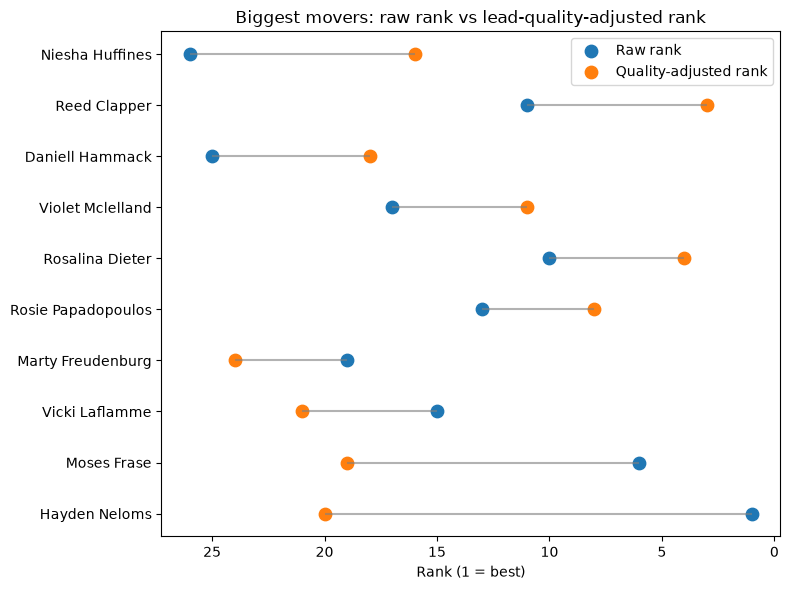

In [25]:
fig, ax = plt.subplots(figsize=(8, 6))
plot_df = biggest_movers.sort_values('rank_shift')

ax.hlines(y=plot_df['sales_agent'], xmin=plot_df['raw_rank'], xmax=plot_df['adjusted_rank'], color='grey', alpha=0.6)
ax.scatter(plot_df['raw_rank'], plot_df['sales_agent'], label='Raw rank', s=80)
ax.scatter(plot_df['adjusted_rank'], plot_df['sales_agent'], label='Quality-adjusted rank', s=80)
ax.invert_xaxis()  # rank 1 on the right feels more like "better"
ax.set_xlabel('Rank (1 = best)')
ax.set_title('Biggest movers: raw rank vs lead-quality-adjusted rank')
ax.legend()
plt.tight_layout()
plt.show()

**Q11 recap, done properly here instead of one long SQL table — per-agent win rate on Outbound leads only, the hardest lead type to close.**

In [26]:
outbound = decided[decided['lead_source'] == 'Outbound']
outbound_perf = outbound.groupby('sales_agent').agg(
    outbound_deals=('won', 'count'),
    outbound_win_rate_pct=('won', lambda x: round(x.mean() * 100, 2))
)
outbound_perf = outbound_perf[outbound_perf['outbound_deals'] >= 5]
outbound_perf.sort_values('outbound_win_rate_pct', ascending=False).head(10)

,outbound_deals,outbound_win_rate_pct
sales_agent,,
Jonathan Berthelot,65,58.46
Moses Frase,38,52.63
Maureen Marcano,39,51.28
Hayden Neloms,38,50.00
Daniell Hammack,43,46.51
Wilburn Farren,22,45.45
Reed Clapper,69,44.93
Versie Hillebrand,58,44.83
James Ascencio,46,43.48


**Q12 recap — average lead score each agent was actually handed.** Mainly here so it sits right next to the win-rate numbers instead of living in a separate table somewhere.

In [27]:
df.groupby('sales_agent')['lead_score'].mean().round(1).sort_values(ascending=False).head(10)

sales_agent
Hayden Neloms        68.7
Garret Kinder        67.8
Anna Snelling        66.2
Moses Frase          66.1
Versie Hillebrand    64.5
Cecily Lampkin       64.5
James Ascencio       64.0
Vicki Laflamme       63.9
Maureen Marcano      63.7
Markita Hansen       62.9
Name: lead_score, dtype: float64

**Q13 — rolling it up to manager and region.**

In [28]:
manager_perf = decided.groupby('manager').agg(
    decided_deals=('won', 'count'),
    won_pct=('won', lambda x: round(x.mean() * 100, 2))
)
manager_perf['total_revenue'] = df[df['deal_stage'] == 'Won'].groupby('manager')['close_value'].sum()
manager_perf.sort_values('won_pct', ascending=False)

,decided_deals,won_pct,total_revenue
manager,,,
Cara Losch,745,64.43,1130049.0
Summer Sewald,1287,64.34,1964750.0
Celia Rouche,962,63.41,1603897.0
Dustin Brinkmann,1186,62.98,1094363.0
Melvin Marxen,1418,62.20,2251930.0
Rocco Neubert,1113,62.08,1960545.0


In [29]:
region_perf = decided.groupby('regional_office').agg(
    decided_deals=('won', 'count'),
    won_pct=('won', lambda x: round(x.mean() * 100, 2))
)
region_perf['total_revenue'] = df[df['deal_stage'] == 'Won'].groupby('regional_office')['close_value'].sum()
region_perf.sort_values('won_pct', ascending=False)

,decided_deals,won_pct,total_revenue
regional_office,,,
West,2249,63.94,3568647.0
East,1858,63.02,3090594.0
Central,2604,62.56,3346293.0


Same pattern that showed up at the individual level shows up again here — Cara Losch's team wins at the highest rate, but Melvin Marxen's team brings in the most total revenue by running a lot more deals at a slightly lower rate. Volume and rate are pulling in different directions, and neither number alone tells the full story.

## Section D — Product and sector, quickly

Already know from SQL these don't move the needle much (everything sits in a 60-65% band), so just confirming that and moving on rather than over-analyzing a flat result.

In [30]:
product_perf = decided.groupby('product').agg(
    decided_deals=('won', 'count'),
    won_pct=('won', lambda x: round(x.mean() * 100, 2))
)
product_perf['avg_close_value'] = df[df['deal_stage'] == 'Won'].groupby('product')['close_value'].mean().round(0)
product_perf.sort_values('won_pct', ascending=False)

,decided_deals,won_pct,avg_close_value
product,,,
MG Special,1223,64.84,55.0
GTX Plus Pro,745,64.30,5490.0
GTX Basic,1436,63.72,546.0
GTX Pro,1147,63.56,4816.0
GTX Plus Basic,1051,62.13,1080.0
MG Advanced,1084,60.33,3389.0
GTK 500,25,60.00,26707.0


In [31]:
sector_perf = decided.groupby('sector').agg(
    decided_deals=('won', 'count'),
    won_pct=('won', lambda x: round(x.mean() * 100, 2))
)
sector_perf.sort_values('won_pct', ascending=False)

,decided_deals,won_pct
sector,,
marketing,623,64.85
entertainment,402,64.68
software,704,63.92
technology,1058,63.42
services,352,63.35
retail,1267,63.06
employment,286,62.59
telecommunications,456,62.50
medical,950,62.32


## What I'm taking away from this

The headline finding is the quality-adjusted rep table. A leaderboard built on raw win rate rewards whoever's queue happens to be full of Referral and Partner leads. Once lead quality gets stripped out properly — using the full quintile model, not just a single-channel proxy — Wilburn Farren and Maureen Marcano turn out to be the strongest closers relative to what they were given, and Garret Kinder, despite good-looking headline numbers, turns out to be the weakest.

Worth remembering for the writeup: my first pass at this (the Outbound-only cut) pointed at different names. It wasn't wrong exactly, just too narrow — one channel isn't enough to call it "quality-adjusted." That's a real finding in itself: quick single-cut comparisons can mislead, and it's worth building the fuller model before trusting a "hidden gem" story.

Everything else — the funnel shape, the source cost/win tradeoff, the product and sector splits — is real and worth a line each in the writeup, but none of it is as sharp or as useful to an actual sales manager as the rep-performance table. That's what the dashboard should be built around.